In [37]:
from argparse import ArgumentParser, Namespace
import Spectral_Preprocessing as sp
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import json

In [38]:
parser = ArgumentParser()
parser.add_argument("--range-ir-1", dest= "wn_range_ir_1", default = (948,1860))
parser.add_argument("--range-ir-2", dest= "wn_range_ir_2", default = (2698,3002))

parser.add_argument("--range-min-ir", dest= "range_min_ir", type = int, default = 400)
parser.add_argument("--range-max-ir", dest= "range_max_ir", type = int, default = 4000)
parser.add_argument("--interpolate-interval-ir", dest = "interpolate_interval_ir", type = int, default = 1) 

parser.add_argument("--finger-print-exl", dest= "finger_print_exl", type = bool, default = False)
parser.add_argument("--trans-chip", dest= "trans_chip", type = bool, default = False)

parser.add_argument("--background-rule-ir", dest= "background_rule", type = str, default = 'mean')
parser.add_argument("--threshold-mean-intensity-ir", dest= "ths_mean_int_ir", type = float, default = 0)
parser.add_argument("--threshold-total-variation-intensity-ir", dest= "ths_tot_var_int_ir", type = float, default = 0)

parser.add_argument("--range-min-raman", dest= "range_min_raman", type = float, default = 400)
parser.add_argument("--range-max-raman", dest= "range_max_raman", type = float, default = 4000)
parser.add_argument("--interpolate-interval-raman", dest = "interpolate_interval_raman", type = float, default = 1) 

parser.add_argument("--rubberband", dest="rubberband", action="store_true", default=False,)
parser.add_argument("--minmax", dest="minmax", action="store_true", default=False,)
parser.add_argument("--no-interpolate", dest = "no_interpolate", action="store_true", default = False)
parser.add_argument("--nitrogen-calibration", dest="nitrogen_calibration", action="store_true", default=True,)
parser.add_argument("--si-peak", dest= "si_peak", type = float, default = 520)

parser.add_argument("--smooth", dest = "smooth", type = int, default = 0)
parser.add_argument("--baseline", dest = "baseline", type = int, default = 5)

###Sample Code #1: Specify IR and Raman interpolation intervals along with min & max values
args: Namespace = parser.parse_args([]) ###Do not alter this section.
###PLEASE TYPE IN YOUR ARGUMENTS HERE
args.wn_range_ir_1 = (980, 1800) #(675.0,1800)
args.wn_range_ir_2 = (2720, 2970) #(1800,4000)
args.range_min_ir = 675.0 #674.9918 ###enter an integer
args.range_max_ir = 4000.0 #3999.809 ###enter an integer [max value is not included]
args.interpolate_interval_ir = 2 #1.929 ###enter an integer
args.finger_print_exl = False
args.trans_chip = True
args.background_rule = 'total_var'
args.ths_mean_int_ir = 0.043
args.ths_tot_var_int_ir = 0.4543#0.59

args.range_min_raman = 355 #.555542 ###enter an integer or float #530
args.range_max_raman = 3500 #3895.935059 ##enter an integer or float [max value is not included] 
args.interpolate_interval_raman = 2.0 #168021680216802 ###enter an integer or float

args.rubberband = 'specy'#'specy' ###True for rubberband, False for iModPoly
args.minmax = 'snv' ###False for SVT normalization, True for minmax
args.no_interpolate = False ###use sample code 2 if using True for this option.
args.nitrogen_calibration = True ##True for calibration, False for no calibration.
args.si_peak = 520 ###enter an integer or float

# Gloves Data

In [62]:
directory_name = 'MEC_02_115/Raw Data/' ###directory where the PTIR files will be downloaded from.
ir_export_filename =  "no_interpolate_equiv_ir.csv"  ###enter your desired export Raman csv filename, in quotes
raman_export_filename =  "no_interpolate_equiv_raman.csv"  ###enter your desired export Raman csv filename, in quotes
file_list_tmp = [] ###option to list out the files you want included. if left as-is, all files in directory will be included.

path = 'MEC_02_115/Raw Data/'
dirs = os.listdir(path)

for d in dirs:
    if d[-4:] == 'ptir' or d==".DS_Store":
        del dirs[np.where(np.array(dirs) == d)[0][0]]
        
files_list = []
for d in dirs:
    files = os.listdir(path + d)
    files_list = files_list + [d+'/'+f for f in files if f[-5:] == '.ptir']
    
raman_final, ir_final, label_list, XX_ir, XX_raman, ids, coords, _, rng, ir_bg_label, saturated_wn_list = sp.ptir_to_interpolated_processed_csv(args, directory_name,
                                                            ir_export_filename, raman_export_filename, 
                                                            file_list = files_list[1:], transpose = True)

NA Rows Removed but no other issues MEC_02_115/Raw Data/MF_L_01/MEC_02_115_MF_L_01_20240514.ptir


/Users/eochoa/Documents/Research_Ambuj/M4AM/spectral_libraries/Spectral_Preprocessing.py:187: RuntimeWarning: invalid value encountered in divide
  return (x - x.mean()) / x.std()
/Users/eochoa/Documents/Research_Ambuj/M4AM/spectral_libraries/Spectral_Preprocessing.py:396: RuntimeWarning: invalid value encountered in scalar divide
  data4 = [(element - np.mean(data2)) / np.std(data2) for element in data2]


NA Rows Removed but no other issues MEC_02_115/Raw Data/FB_N_02/MEC_02_115_FB_N_02_20240404.ptir


/Users/eochoa/Documents/Research_Ambuj/M4AM/spectral_libraries/Spectral_Preprocessing.py:187: RuntimeWarning: invalid value encountered in divide
  return (x - x.mean()) / x.std()
/Users/eochoa/Documents/Research_Ambuj/M4AM/spectral_libraries/Spectral_Preprocessing.py:187: RuntimeWarning: invalid value encountered in divide
  return (x - x.mean()) / x.std()


NA Rows Removed but no other issues MEC_02_115/Raw Data/MF_N_01/MEC_02_115_MF_N_01_20240405.ptir


/Users/eochoa/Documents/Research_Ambuj/M4AM/spectral_libraries/Spectral_Preprocessing.py:187: RuntimeWarning: invalid value encountered in divide
  return (x - x.mean()) / x.std()


In [40]:
#with open('gloves_contamination/gloves_data_raman_saturation.json', 'r') as f:
#    saturated_wn_dict_1 = json.load(f)

In [65]:
saturated_wn_dict

{'MF_L_01_0514_17': '62, 63, 64, 65, 66, 67, 68, 69, 70',
 'MF_L_01_0514_18': '24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 250, 251, 252, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275',
 'MF_L_01_0514_19': '33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56',
 'MF_L_01_0514_20': '78, 79, 80, 81',
 'MF_L_01_0514_21': '0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 

In [64]:
ids_file_name = np.array([x[19:-13] + x[-9:-5] 
                 if x[7] == '/' else x[20:-17] + '_' + '-'+x[-17:-13] + x[-9:-5] # x[20:-5] 
                 for x in ids])
ids_file_name = ids_file_name.astype('<U20')
ids_file_name_list = np.unique(ids_file_name)

idx_ = []
i = 1
for j, x in enumerate(ids_file_name):
    #idx_.append(i)
    ids_file_name[j] = x +'_'+ str(i)
    if j < ids_file_name.shape[0]-1 and x != ids_file_name[j+1]:
        i = 1
    else:
        i = i + 1

nas_list = np.unique(np.where(np.isnan(raman_final))[0])
non_nas_idx = [x not in nas_list for x in range(raman_final.shape[0])]

saturated_wn_dict = {id_:str(list(x))[1:-1] for x, id_ in zip(saturated_wn_list,ids_file_name) if x.shape[0]>0}
saturated_wn_dict
with open('gloves_contamination/gloves_data_raman_saturation.json', 'w') as f:
    json.dump(saturated_wn_dict, f)
    
preposs_data_ir = pd.DataFrame(ir_final)
preposs_data_ir.columns = XX_ir
preposs_data_ir = pd.concat([preposs_data_ir, coords], axis=1)
preposs_data_ir['id'] = ids_file_name
preposs_data_ir['background'] = ir_bg_label
preposs_data_ir.loc[non_nas_idx, :]
#preposs_data_ir.to_csv('gloves_contamination/gloves_data_ir_final.csv')

preposs_data_raman = pd.DataFrame(raman_final)
preposs_data_raman.columns = XX_raman
preposs_data_raman = pd.concat([preposs_data_raman, coords], axis=1)
preposs_data_raman['id'] = ids_file_name
preposs_data_raman = preposs_data_raman.loc[np.array(non_nas_idx), :].reset_index(drop=True)
preposs_data_raman.to_csv('gloves_contamination/gloves_data_raman_final_specy.csv')

In [6]:
np.unique(preposs_data_ir['background'])

array(['background', 'no_background'], dtype=object)

# Stearates Data

In [51]:
directory_name = 'MEC_04_010/Raw Data/Stearates/' ###directory where the PTIR files will be downloaded from.
ir_export_filename =  "no_interpolate_equiv_ir.csv"  ###enter your desired export Raman csv filename, in quotes
raman_export_filename =  "no_interpolate_equiv_raman.csv"  ###enter your desired export Raman csv filename, in quotes
file_list_tmp = [] ###option to list out the files you want included. if left as-is, all files in directory will be included.

path = 'MEC_04_010/Raw Data/Stearates/'
dirs = os.listdir(path)

for d in dirs:
    if d[-4:] == 'ptir' or d==".DS_Store":
        del dirs[np.where(np.array(dirs) == d)[0][0]]
        
files_list = []
for d in dirs:
    files = os.listdir(path + d)
    files_list = files_list + [d+'/'+f for f in files if f[-5:] == '.ptir']
    
raman_final, ir_final, label_list, XX_ir, XX_raman, ids, coords, _, rng, ir_bg_label, saturated_wn_list = sp.ptir_to_interpolated_processed_csv(args, directory_name,
                                                            ir_export_filename, raman_export_filename, 
                                                            file_list = files_list, transpose = True)

/Users/eochoa/Documents/Research_Ambuj/M4AM/spectral_libraries/Spectral_Preprocessing.py:396: RuntimeWarning: invalid value encountered in scalar divide
  data4 = [(element - np.mean(data2)) / np.std(data2) for element in data2]
/Users/eochoa/Documents/Research_Ambuj/M4AM/spectral_libraries/Spectral_Preprocessing.py:229: RuntimeWarning: divide by zero encountered in scalar divide
  criteria = abs((dev_curr - devPrev) / dev_curr) <= 0.05
/Users/eochoa/Documents/Research_Ambuj/M4AM/spectral_libraries/Spectral_Preprocessing.py:229: RuntimeWarning: invalid value encountered in scalar divide
  criteria = abs((dev_curr - devPrev) / dev_curr) <= 0.05
/Users/eochoa/Documents/Research_Ambuj/M4AM/spectral_libraries/Spectral_Preprocessing.py:187: RuntimeWarning: invalid value encountered in divide
  return (x - x.mean()) / x.std()
/Users/eochoa/Documents/Research_Ambuj/M4AM/spectral_libraries/Spectral_Preprocessing.py:229: RuntimeWarning: divide by zero encountered in scalar divide
  criteria = a

In [52]:
ids_file_name = np.array([x[:x.find('/')] for x in ids])
labels_file_name = np.array([x[:x.find('/')] for x in ids])

ids_file_name = ids_file_name.astype('<U30')
ids_file_name_list = np.unique(ids_file_name)

idx_ = []
i = 1
for j, x in enumerate(ids_file_name):
    #idx_.append(i)
    ids_file_name[j] = x +'_'+ str(i)
    if j < ids_file_name.shape[0]-1 and x != ids_file_name[j+1]:
        i = 1
    else:
        i = i + 1

In [53]:
material_list = ['Magnesium Stearate v2',
                 'Calcium Stearate',  
                 'Sodium Stearate',  
                 'Zinc Stearate']

material_sheets =['Mg (v2)', 'Ca', 'Na', 'Zn']
df_st_in_lib_ir_list = []
for mat, sheet in zip(material_list, material_sheets):
    df_st_in_lib_ir = pd.read_excel('gloves_contamination/MEC_04_010_StearateLibrary_Compilation.xlsx', sheet_name=sheet)
    df_st_in_lib_ir = df_st_in_lib_ir.iloc[:-2,:2]#['Number']
    df_st_in_lib_ir['id'] = [mat+ '_' + str(x) for x in df_st_in_lib_ir['Number']]
    df_st_in_lib_ir = df_st_in_lib_ir.loc[:,['id', 'PTIR']]
    df_st_in_lib_ir.columns = ['id', 'in_library']
    df_st_in_lib_ir_list.append(df_st_in_lib_ir)    
df_st_in_lib_ir = pd.concat(df_st_in_lib_ir_list, axis=0)
df_st_in_lib_ir = df_st_in_lib_ir.query('in_library == 1').reset_index(drop=True)

df_st_in_lib_raman_list = []

for mat, sheet in zip(material_list, material_sheets):
    df_st_in_lib_raman = pd.read_excel('gloves_contamination/MEC_04_010_StearateLibrary_Compilation.xlsx', sheet_name=sheet)
    df_st_in_lib_raman = df_st_in_lib_raman.iloc[:-2,[0,3]]#['Number']
    df_st_in_lib_raman['id'] = [mat+ '_' + str(x) for x in df_st_in_lib_raman['Number']]
    df_st_in_lib_raman = df_st_in_lib_raman.loc[:,['id', 'Raman']]
    df_st_in_lib_raman.columns = ['id', 'in_library']
    df_st_in_lib_raman_list.append(df_st_in_lib_raman)
df_st_in_lib_raman = pd.concat(df_st_in_lib_raman_list, axis=0)
df_st_in_lib_raman = df_st_in_lib_raman.query('in_library == 1').reset_index(drop=True)
in_library_ids = list(df_st_in_lib_raman['id'])

In [54]:
saturated_wn_dict = {id_:str(list(x))[1:-1] for x, id_ in zip(saturated_wn_list,ids_file_name) if x.shape[0]>0}
saturated_wn_dict = {key:saturated_wn_dict[key] for key in saturated_wn_dict.keys() if key in in_library_ids}# in_library_ids
with open('gloves_contamination/stearates_data_raman_saturation.json', 'w') as f:
    json.dump(saturated_wn_dict, f)

In [55]:
preposs_data_raman = pd.DataFrame(raman_final)
preposs_data_raman.columns = XX_raman
preposs_data_raman = pd.concat([preposs_data_raman, coords], axis=1)
preposs_data_raman['polymer'] = labels_file_name
preposs_data_raman['id'] = ids_file_name
preposs_data_raman = preposs_data_raman.merge(df_st_in_lib_raman).drop('in_library',axis=1).reset_index(drop=True)
preposs_data_raman.to_csv('gloves_contamination/stearates_data_raman_final_specy.csv')

preposs_data_ir = pd.DataFrame(ir_final)
preposs_data_ir.columns = XX_ir
preposs_data_ir = pd.concat([preposs_data_ir, coords], axis=1)
preposs_data_ir['polymer'] = labels_file_name
preposs_data_ir['id'] = ids_file_name
preposs_data_ir = preposs_data_ir.merge(df_st_in_lib_ir).drop('in_library',axis=1).reset_index(drop=True)
#preposs_data_ir.to_csv('gloves_contamination/stearates_data_ir_final.csv')

# Rebecca Data

In [56]:
#directory_name = '/Users/eochoa/Documents/Research_Ambuj/M4AM/spectral_libraries/MEC_02_115/Raw Data/' ###directory where the PTIR files will be downloaded from.
directory_name = 'MEC_02_115/Raw Data/' ###directory where the PTIR files will be downloaded from.
ir_export_filename =  "no_interpolate_equiv_ir.csv"  ###enter your desired export Raman csv filename, in quotes
raman_export_filename =  "no_interpolate_equiv_raman.csv"  ###enter your desired export Raman csv filename, in quotes
file_list_tmp = [] ###option to list out the files you want included. if left as-is, all files in directory will be included.

path = 'Reference_library_reb/'
dirs = os.listdir(path)
dirs = [x for x in dirs if x not in ['.DS_Store', 'Archive for reference data', 'Processed']]

file_list = []
for d in dirs:
    #print(os.listdir(path + d + '/Data/Processed/mIRage OPTIR+Raman/'))
    path_2 = path + d + '/Data/Processed/mIRage OPTIR+Raman/'
    dirs_2 = os.listdir(path_2)
    #file_list = file_list + [path_2 + dd for dd in dirs_2 if dd[-4:] == "xlsx"]
    file_list = file_list + [path_2 + dd for dd in dirs_2 if (dd[-9:] == "data.xlsx" or dd[-12:] == "spectra.xlsx")]
file_list = file_list + [d + '/' + dd for dd in dirs_2 if (dd[-9:] == "data.xlsx" or dd[-12:] == "spectra.xlsx")]

polymer_list = np.array(['sucrose', 'PE', 'PSL', 'NaNO3', 'NH2SO4', 'PP'])

wn_list = []
df_list = []
for i, f in enumerate(file_list):
    df = pd.read_excel(f, sheet_name=None)#['Raman', 'Raman spectra']
    print(f)
    if 'Raman' in df.keys():
        df_raman = df['Raman']
    elif 'Raman spectra' in df.keys():
        df_raman = df['Raman spectra']
    df_raman.columns = ['wavenumber'] + list(range(df_raman.shape[1]-1))#.set_index('X value [cmâ»Â¹]')
    df_raman = df_raman.set_index('wavenumber')
    df_raman = df_raman.T.reset_index(drop=True)
    df_raman['polymer'] = polymer_list[[p in f for p in polymer_list]][0]#polymer[i]
    df_raman['map_x'] = 0
    df_raman['map_y'] = 0
    
    if 'O-PTIR' in df.keys():
        df_ir = df['O-PTIR']
    elif 'PTIR spectra' in df.keys():
        df_ir = df['PTIR spectra']
    df_ir.columns = ['wavenumber'] + list(range(df_ir.shape[1]-1))#.set_index('X value [cmâ»Â¹]')
    df_ir = df_ir.set_index('wavenumber')
    df_ir = df_ir.T.reset_index(drop=True)
    df_ir['polymer'] = polymer_list[[p in f for p in polymer_list]][0]#polymer[i]
    df_ir['map_x'] = 0
    df_ir['map_y'] = 0
    
    df_list.append([df_ir,df_raman])
    
pol_table = pd.DataFrame({'file':[polymer_list[[p in f for p in polymer_list]][0] for f in file_list]})

raman_final, ir_final, label_list, XX_ir, XX_raman, ids, coords, _, rng, ir_bg_label, saturated_wn_list = sp.df_to_interpolated_processed_csv(args, directory_name=None, ir_export_filename=None, raman_export_filename=None, file_list = df_list, transpose = True)


Reference_library_reb/20230708 0.05 M sucrose/Data/Processed/mIRage OPTIR+Raman/20240509_50mMsucrose_RP_mIRage_allccdata.xlsx
Reference_library_reb/20230423 1.0 and 3.0 um PSL/Data/Processed/mIRage OPTIR+Raman/20230424_1and3umPSL_allccdata.xlsx
Reference_library_reb/20230708 0.05 M NaNO3/Data/Processed/mIRage OPTIR+Raman/20240509_50mMNaNO3_RP_mIRage_allccdata.xlsx
Reference_library_reb/20230707 200 to 9900 nm PE EtOH iced atomized/Data/Processed/mIRage OPTIR+Raman/20230707_200to9900nmPE_EtOHiced_atomized_mIRage_allccdata.xlsx
Reference_library_reb/20230708 0.05 M NH2SO4/Data/Processed/mIRage OPTIR+Raman/20240509_50mMNH42SO4_RP_mIRage_allccdata.xlsx
Reference_library_reb/20230906 1 to 5 um PP 50-50 EtOH-Omni 2 min sonication iced/Data/Processed/mIRage OPTIR+Raman/20230906_1to5umPP_2minsonic_iced_30minMPSstg2_allspectra.xlsx


In [57]:
id_list = np.array(label_list, dtype='<U15')
for poly in np.unique(label_list):
    n = sum(np.array(label_list) == poly)
    id_list[id_list==poly] = [poly+'_'+str(i+1) for i in range(n)]

In [58]:
material_list = ['PSL', 'PE', 'PP']

material_sheets = ['PSL', 'PE', 'PP']
df_st_in_lib_ir_list = []
for mat, sheet in zip(material_list, material_sheets):
    df_st_in_lib_ir = pd.read_excel('gloves_contamination/MEC_04_017_Raman_and_PTIR_PSL_PP_PE_Library_Sorted.xlsx', sheet_name=sheet)
    df_st_in_lib_ir = df_st_in_lib_ir.iloc[:-1,:2]#['Number']
    df_st_in_lib_ir['id'] = [mat+ '_' + str(int(x)) for x in df_st_in_lib_ir['ID']]
    df_st_in_lib_ir = df_st_in_lib_ir.loc[:,['id', 'PTIR']]
    df_st_in_lib_ir.columns = ['id', 'in_library']
    df_st_in_lib_ir_list.append(df_st_in_lib_ir)    
df_st_in_lib_ir = pd.concat(df_st_in_lib_ir_list, axis=0)
df_st_in_lib_ir = df_st_in_lib_ir.query('in_library == 1').reset_index(drop=True)

df_st_in_lib_raman_list = []
for mat, sheet in zip(material_list, material_sheets):
    df_st_in_lib_raman = pd.read_excel('gloves_contamination/MEC_04_017_Raman_and_PTIR_PSL_PP_PE_Library_Sorted.xlsx', sheet_name=sheet)
    df_st_in_lib_raman = df_st_in_lib_raman.iloc[:-1,[0,3]]#['Number']
    df_st_in_lib_raman['id'] = [mat+ '_' + str(int(x)) for x in df_st_in_lib_raman['ID']]
    df_st_in_lib_raman = df_st_in_lib_raman.loc[:,['id', 'Raman']]
    df_st_in_lib_raman.columns = ['id', 'in_library']
    df_st_in_lib_raman_list.append(df_st_in_lib_raman)
df_st_in_lib_raman = pd.concat(df_st_in_lib_raman_list, axis=0)
df_st_in_lib_raman = df_st_in_lib_raman.query('in_library == 1').reset_index(drop=True)

In [59]:
preposs_data_raman = pd.DataFrame(raman_final)
preposs_data_raman.columns = XX_raman
preposs_data_raman = pd.concat([preposs_data_raman, coords], axis=1)
preposs_data_raman['polymer'] = label_list
preposs_data_raman['id'] = id_list
preposs_data_raman = preposs_data_raman.merge(df_st_in_lib_raman).drop('in_library',axis=1).reset_index(drop=True)
preposs_data_raman.to_csv('gloves_contamination/rebecca_data_raman_final_specy.csv')

preposs_data_ir = pd.DataFrame(ir_final)
preposs_data_ir.columns = XX_ir
preposs_data_ir = pd.concat([preposs_data_ir, coords], axis=1)
preposs_data_ir['polymer'] = label_list
preposs_data_ir['id'] = id_list
preposs_data_ir = preposs_data_ir.merge(df_st_in_lib_ir).drop('in_library',axis=1).reset_index(drop=True)
#preposs_data_ir.to_csv('gloves_contamination/rebecca_data_ir_final.csv')

# Flopp and Slopp Data

In [29]:
flopp_df = pd.read_csv('gloves_contamination/flopp_flopp_e_for_preprocess_no_trans.csv')
id_s = flopp_df.loc[:,'file_name']
polymer = flopp_df.loc[:,'polymer']
flopp_df = flopp_df.drop(['Unnamed: 0', 'file_name', 'data_source'], axis=1)
flopp_df = flopp_df.iloc[:,list(range(1,flopp_df.shape[1]))+[0]]
flopp_df['map_x'] = 0
flopp_df['map_y'] = 0
raman_final, ir_final, label_list, XX_ir, XX_raman, ids, coords, _, rng, ir_bg_label, saturated_wn_list = sp.df_to_interpolated_processed_csv(args, directory_name=None, ir_export_filename=None, raman_export_filename=None, file_list = [[flopp_df,flopp_df]], transpose = True)

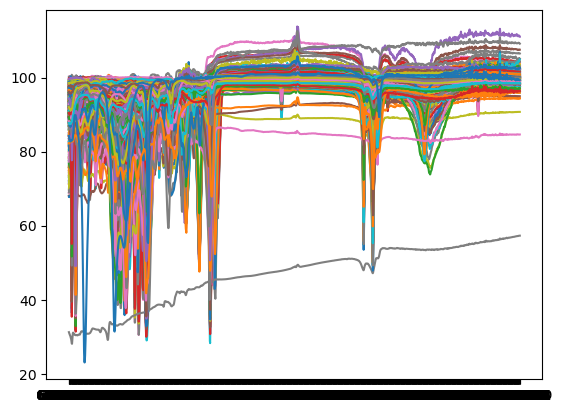

In [31]:
_ = plt.plot(flopp_df.iloc[:,:-3].T)

In [32]:
preposs_data_ir = pd.DataFrame(ir_final)
preposs_data_ir.columns = XX_ir
preposs_data_ir = pd.concat([preposs_data_ir, coords], axis=1)
preposs_data_ir['polymer'] = label_list
preposs_data_ir['id'] = np.array(id_s)
#preposs_data_ir.to_csv('gloves_contamination/flopp_data_ir_final.csv')

In [33]:
flopp_df = pd.read_csv('gloves_contamination/flopp_flopp_e_for_preprocess_no_trans.csv')
preposs_data_ir['data_source'] = np.array(flopp_df['data_source'])
preposs_data_ir

,675.0,677.0,679.0,681.0,683.0,685.0,687.0,689.0,691.0,693.0,...,3991.0,3993.0,3995.0,3997.0,3999.0,map_x,map_y,polymer,id,data_source
0,91.828721,91.675547,91.584489,91.349623,91.028427,90.629750,90.011628,88.992518,87.230688,84.168543,...,100.054898,100.069505,100.051499,100.026184,100.032899,0,0,Acrylonitrile Butadiene Styrene,ABS 1. Orange LEGO Fragment.CSV,flopp
1,87.536299,87.341932,87.061672,86.742586,86.300610,85.606212,84.695937,83.226930,80.391332,75.405789,...,100.375046,100.363850,100.363570,100.370928,100.376132,0,0,Acrylonitrile Butadiene Styrene,ABS 10. Brown LEGO Fragment.CSV,flopp
2,89.228530,89.047059,88.897583,88.591637,88.244359,87.647664,86.742063,85.366814,82.960842,78.604529,...,99.794030,99.799871,99.781065,99.749285,99.740553,0,0,Acrylonitrile Butadiene Styrene,ABS 11. Black LEGO Fragment.CSV,flopp
3,78.517179,78.515554,78.533076,78.458066,78.167761,77.817938,77.301646,76.422268,74.555815,70.956756,...,98.528040,98.516067,98.510491,98.500108,98.497811,0,0,Acrylonitrile Butadiene Styrene,ABS 12. White LEGO Fragment.CSV,flopp
4,86.588043,86.496522,86.525001,86.375774,85.912762,85.354381,84.758227,83.967626,82.227700,78.883073,...,97.843344,97.849943,97.841983,97.824724,97.816226,0,0,Acrylonitrile Butadiene Styrene,ABS 14. White Fridge Lining Fragment.CSV,flopp
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
376,88.204214,87.848246,87.464735,87.468837,87.511521,87.576748,87.594638,87.604480,87.794846,88.100520,...,99.016492,99.004785,99.020674,99.028780,99.023381,0,0,Polyvinyl Chloride,PVC 6. Clear Film.CSV,flopp_e
377,92.300346,91.961533,91.629533,91.521382,91.456545,91.437924,91.384799,91.306727,91.246527,91.217533,...,99.976137,99.963344,99.951613,99.947396,99.951938,0,0,Polyvinyl Chloride,PVC 7. Green Film.CSV,flopp_e
378,92.024226,91.874890,91.637553,91.517875,91.508730,91.479276,91.217976,91.110201,91.165094,91.244856,...,99.516653,99.522776,99.541590,99.542042,99.540606,0,0,Polyvinyl Chloride,PVC 8. Grey Fragment.CSV,flopp_e
379,87.741575,87.571831,87.422980,87.460110,87.457230,87.497609,87.490730,87.575532,87.715063,87.881896,...,98.513567,98.542726,98.539818,98.495668,98.451203,0,0,Polyvinyl Chloride,PVC 9. White Fragment.CSV,flopp_e


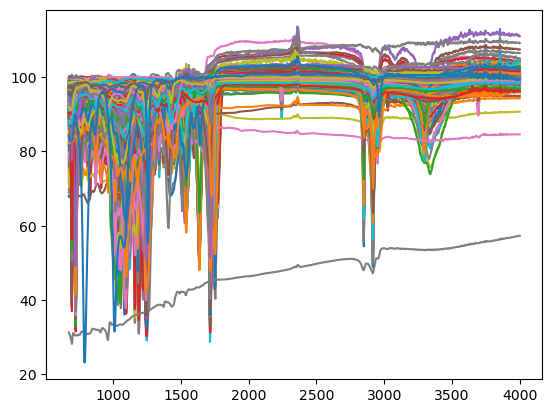

In [34]:
_ = plt.plot(preposs_data_ir.iloc[:,:-5].T)

In [35]:
preposs_data_ir.to_csv('gloves_contamination/flopp_data_ir_final_transmission.csv')

In [60]:
slopp_df = pd.read_csv('processed_data/slopp_slopp_e_pivot.csv')
id_s = slopp_df.loc[:,'file_name']
slopp_df = slopp_df.drop(['Unnamed: 0', 'file_name', 'data_source'], axis=1)
#slopp_df.columns = list(slopp_df.columns[:2]) + list(np.float64(slopp_df.columns[2:-1])) + [slopp_df.columns[1]]
slopp_df = slopp_df.iloc[:,list(range(1,slopp_df.shape[1]))+[0]]
slopp_df['map_x'] = 0
slopp_df['map_y'] = 0
raman_final, ir_final, label_list, XX_ir, XX_raman, ids, coords, _, rng, ir_bg_label, saturated_wn_list = sp.df_to_interpolated_processed_csv(args, directory_name=None, ir_export_filename=None, raman_export_filename=None, file_list = [[slopp_df,slopp_df]], transpose = True)


/Users/eochoa/Documents/Research_Ambuj/M4AM/spectral_libraries/Spectral_Preprocessing.py:396: RuntimeWarning: invalid value encountered in scalar divide
  data4 = [(element - np.mean(data2)) / np.std(data2) for element in data2]


In [61]:
preposs_data_raman = pd.DataFrame(raman_final)
preposs_data_raman.columns = XX_raman
preposs_data_raman = pd.concat([preposs_data_raman, coords], axis=1)
preposs_data_raman['polymer'] = label_list
preposs_data_raman['id'] = id_s
preposs_data_raman.to_csv('gloves_contamination/slopp_data_raman_final_specy.csv')